## <b>Intelligence Artificielle pour la Mobilité Autonome -> Notebook d'exercices n°1c</b>

## <b>Exercice 1.5 : Algorithme de clustering</b>

Appliquer les algorithmes K-Means et GMM (Gaussian Mixture Model) aux données <b>Breast Cancer</b> et comparer les clusters estimés avec les vrais clusters (c'est à dire les 2 groupes de données appartenant aux 2 classes : bénin et malin).  
Le regroupements seront visualisés en 3D à partir d'une projection de type <b>Analyse en Composantes Principales</b>, en <b>2D</b> puis en <b>3D</b>.  
Dans les 2 cas, afficher les critères d'évaluation <b>Adjusted Rand Index</b>, <b>Homogénéïté</b> et <b>Complétude</b>.

### <b>a) K-Means</b>

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


[1 1 1 0 1 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 1 1 1 1 0 1 1 1 1 0
 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0
 0 1 0 1 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 1 0 1 0 1
 0 1 1 1 0 1 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0
 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1
 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0
 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 0 0 0 1 1 

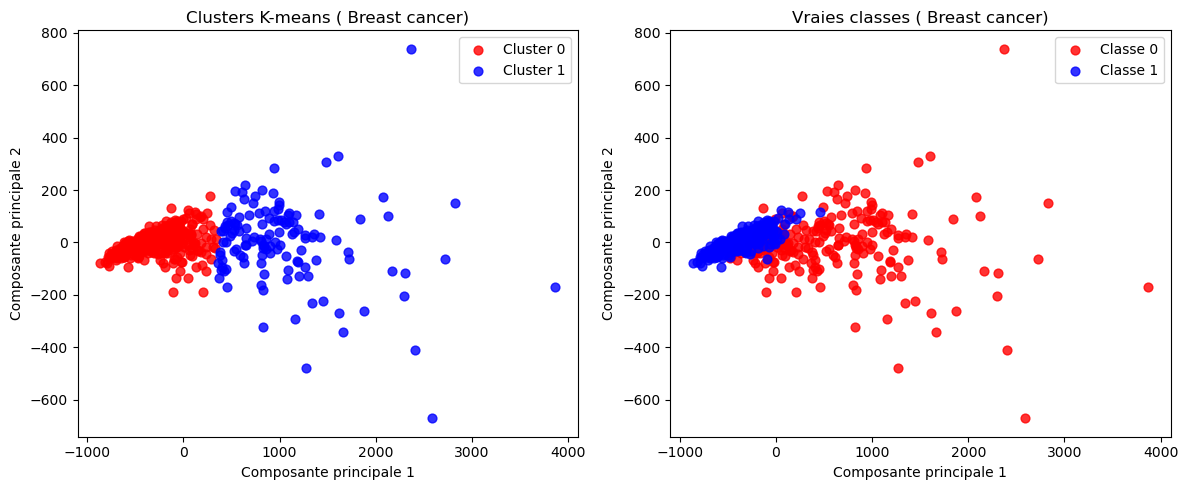

In [4]:
from sklearn.cluster import KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Charger l'ensemble de données cancer
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Application du clustering K-means
kmeans_cancer = KMeans(n_clusters=2, random_state=42)
pred_kmeans_cancer = kmeans_cancer.fit_predict(X)
print(pred_kmeans_cancer)

# Réduire la dimensionnalité avec ACP (PCA) en 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Créer la figure
fig = plt.figure(figsize=(12, 5))
colors = ['red', 'blue']

# Graphique des clusters K-means
ax1 = fig.add_subplot(1, 2, 1)
for i in range(2):
    ax1.scatter(X_pca[pred_kmeans_cancer == i, 0],
                X_pca[pred_kmeans_cancer == i, 1],
                color=colors[i], label=f'Cluster {i}', s=40, alpha=0.8)
ax1.set_title('Clusters K-means ( Breast cancer)')
ax1.set_xlabel('Composante principale 1')
ax1.set_ylabel('Composante principale 2')
ax1.legend()

# Graphique des vraies classes
ax2 = fig.add_subplot(1, 2, 2)
for i in range(2):
    ax2.scatter(X_pca[y == i, 0],
                X_pca[y == i, 1],
                color=colors[i], label=f'Classe {i}', s=40, alpha=0.8)
ax2.set_title('Vraies classes ( Breast cancer)')
ax2.set_xlabel('Composante principale 1')
ax2.set_ylabel('Composante principale 2')
ax2.legend()

plt.tight_layout()
plt.show()

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


[1 1 1 0 1 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 1 1 1 1 0 1 1 1 1 0
 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0
 0 1 0 1 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 1 0 1 0 1
 0 1 1 1 0 1 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0
 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1
 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0
 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 0 0 0 1 1 

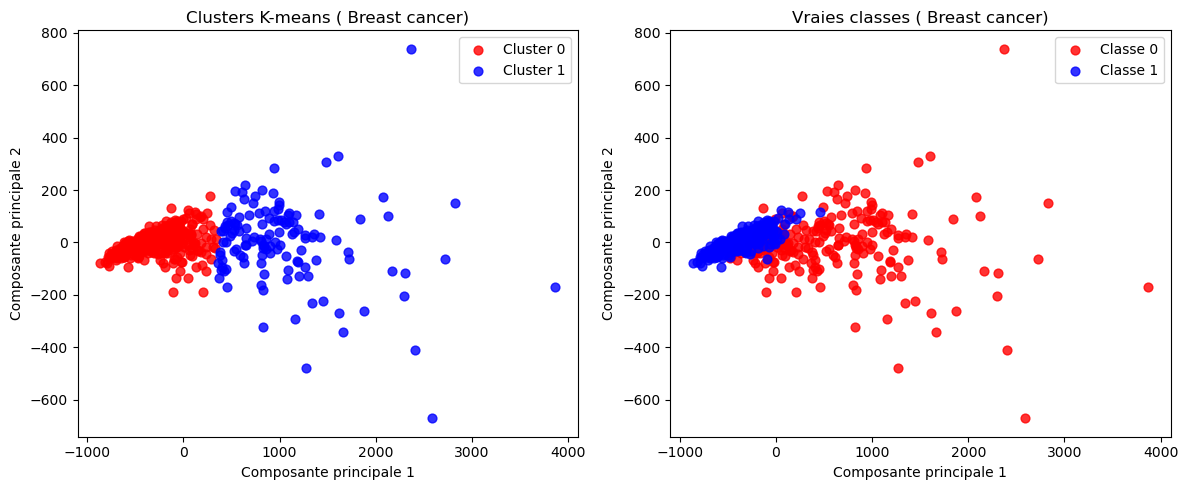

In [4]:
from sklearn.cluster import KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Charger l'ensemble de données cancer
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Application du clustering K-means
kmeans_cancer = KMeans(n_clusters=2, random_state=42)
pred_kmeans_cancer = kmeans_cancer.fit_predict(X)
print(pred_kmeans_cancer)

# Réduire la dimensionnalité avec ACP (PCA) en 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Créer la figure
fig = plt.figure(figsize=(12, 5))
colors = ['red', 'blue']

# Graphique des clusters K-means
ax1 = fig.add_subplot(1, 2, 1)
for i in range(2):
    ax1.scatter(X_pca[pred_kmeans_cancer == i, 0],
                X_pca[pred_kmeans_cancer == i, 1],
                color=colors[i], label=f'Cluster {i}', s=40, alpha=0.8)
ax1.set_title('Clusters K-means ( Breast cancer)')
ax1.set_xlabel('Composante principale 1')
ax1.set_ylabel('Composante principale 2')
ax1.legend()

# Graphique des vraies classes
ax2 = fig.add_subplot(1, 2, 2)
for i in range(2):
    ax2.scatter(X_pca[y == i, 0],
                X_pca[y == i, 1],
                color=colors[i], label=f'Classe {i}', s=40, alpha=0.8)
ax2.set_title('Vraies classes ( Breast cancer)')
ax2.set_xlabel('Composante principale 1')
ax2.set_ylabel('Composante principale 2')
ax2.legend()

plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import adjusted_rand_score, homogeneity_score, completeness_score

ari = adjusted_rand_score(y, pred_kmeans_cancer)
homogeneity = homogeneity_score(y, pred_kmeans_cancer)
completeness = completeness_score(y, pred_kmeans_cancer)

print(f"Adjusted Rand Index : {ari:.3f}")
print(f"Homogénéité : {homogeneity:.3f}")
print(f"Complétude : {completeness:.3f}")

Adjusted Rand Index : 0.491
Homogénéité : 0.422
Complétude : 0.517


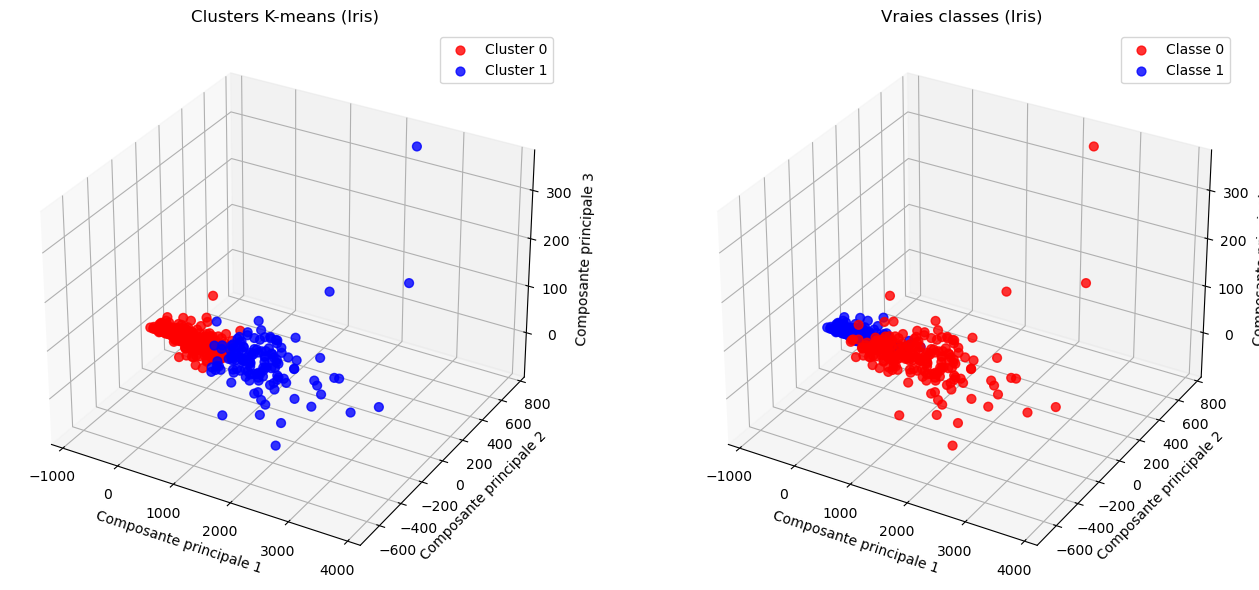

In [7]:
from sklearn.cluster import KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Charger l'ensemble de données cancer
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Réduire la dimensionnalité avec ACP en 3D
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

# Visualiser les clusters en 3D
fig = plt.figure(figsize=(14, 6))

# Graphique des clusters K-means en 3D
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
colors = ['red', 'blue']
for i in range(2):
    ax1.scatter(X_pca[pred_kmeans_cancer == i, 0], X_pca[pred_kmeans_cancer == i, 1], X_pca[pred_kmeans_cancer == i, 2],
                color=colors[i], label=f'Cluster {i}', s=40, alpha=0.8)
ax1.set_title('Clusters K-means (Iris)')
ax1.set_xlabel('Composante principale 1')
ax1.set_ylabel('Composante principale 2')
ax1.set_zlabel('Composante principale 3')
ax1.legend()

# Graphique des vraies classes en 3D
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for i in range(2):
    ax2.scatter(X_pca[y == i, 0], X_pca[y == i, 1], X_pca[y == i, 2], color=colors[i], label=f'Classe {i}', s=40, alpha=0.8)
ax2.set_title('Vraies classes (Iris)')
ax2.set_xlabel('Composante principale 1')
ax2.set_ylabel('Composante principale 2')
ax2.set_zlabel('Composante principale 3')
ax2.legend()

plt.tight_layout()
plt.show()

##### <b>Commentaires :</b>
On obtient 49% de correpondance pour l'ARI ce qui est un résultat plutôt faible. De plus, on constate la présence de faux négatifs ce qui est très dangereux dans le domaine médical.

### <b>b) Gaussian Mixture Models</b>

Adjusted Rand Index : 0.812
Homogénéité : 0.703
Complétude : 0.709


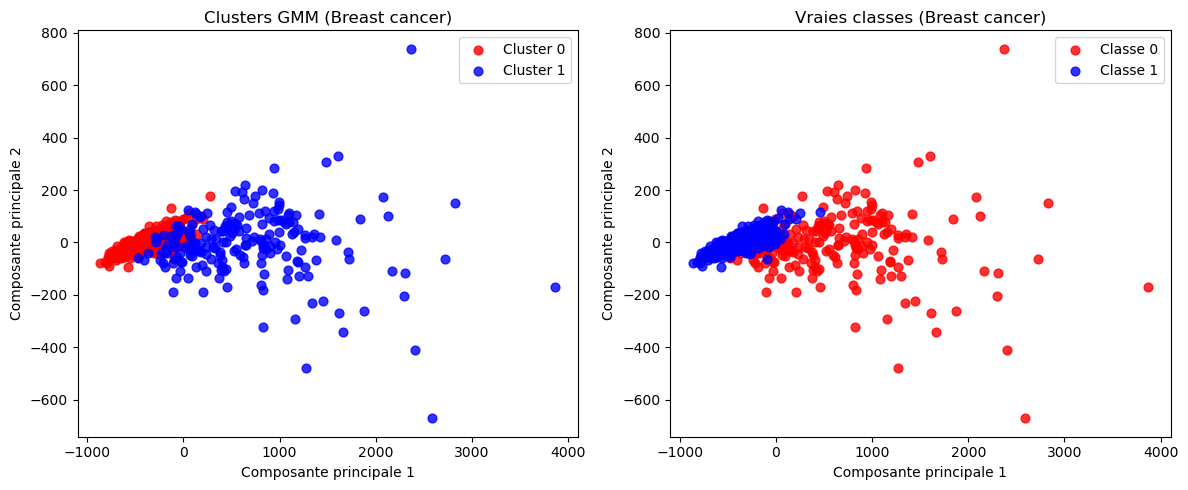

In [9]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, homogeneity_score, completeness_score

# Charger l'ensemble de données cancer
cancer = load_breast_cancer()
X = cancer.data  # Caractéristiques
y = cancer.target  # Vraies classes

# Réduire la dimensionnalité avec ACP en 2D pour la visualisation
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Appliquer GMM
gmm = GaussianMixture(n_components=2, random_state=42)
pred_gmm = gmm.fit_predict(X)

# Calculer les métriques de comparaison avec les vraies classes
ari = adjusted_rand_score(y, pred_gmm)
homogeneity = homogeneity_score(y, pred_gmm)
completeness = completeness_score(y, pred_gmm)

# Afficher les métriques
print(f"Adjusted Rand Index : {ari:.3f}")
print(f"Homogénéité : {homogeneity:.3f}")
print(f"Complétude : {completeness:.3f}")

# Visualiser les clusters GMM et les vraies classes
plt.figure(figsize=(12, 5))

# Graphique des clusters GMM
plt.subplot(1, 2, 1)
colors = ['red', 'blue']
for i in range(2):
    plt.scatter(X_pca[pred_gmm == i, 0], X_pca[pred_gmm == i, 1], color=colors[i], label=f'Cluster {i}', s=40, alpha=0.8)
plt.title('Clusters GMM (Breast cancer)')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.legend()

# Graphique des vraies classes
plt.subplot(1, 2, 2)
for i in range(2):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], color=colors[i], label=f'Classe {i}', s=40, alpha=0.8)
plt.title('Vraies classes (Breast cancer)')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.legend()

plt.tight_layout()
plt.show()

##### <b>Commentaires :</b>

On obtient 81% de correpondance pour l'ARI c, les clusters GMM font donc des regroupement beaucoup plus fidèles aux vraies classes que les K-means.On constate ici la présence de faux positifs.